In [1]:
!pip install --upgrade keras
%pip install tensorflow

  Using cached numpy-1.26.4-cp312-cp312-macosx_10_9_x86_64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-macosx_10_9_x86_64.whl (20.3 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.4
    Uninstalling numpy-2.5.4:
      Successfully uninstalled numpy-2.5.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
contourpy 1.4.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import keras

2026-10-16 21:22:58.447971: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

In [4]:
X_train.shape

(60000, 28, 28)

In [5]:
y_train.shape

(60000,)

In [6]:
X_test.shape

(10000, 28, 28)

In [7]:
y_test.shape

(10000,)

In [8]:
assert X_train.shape == (60000,28,28)

In [9]:
assert y_train.shape == (60000,)

In [10]:
assert X_test.shape == (10000, 28, 28)

In [11]:
assert y_test.shape == (10000,)


## Data Preparation

In [12]:
X_train[10000]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,  29, 150, 195, 254,
        255, 254, 176, 193, 150,  96,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  

In [13]:
pip install matplotlib

  Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_x86_64.whl.metadata (6.6 kB)
Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_x86_64.whl (6.8 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.16.2 requires numpy<2.0.0,>=1.26.0; python_version >= "3.12", but you have numpy 2.5.4 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [14]:
from matplotlib import pyplot as plt

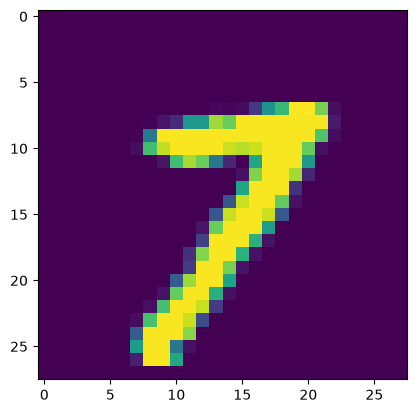

In [15]:
plt.imshow(X_train[40000])
plt.show()

In [16]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.


## Normalize the data

In [17]:
X_train.min(), X_train.max()

(0, 255)

In [18]:
X_test.min(), X_test.max()

(0, 255)

In [19]:
X_train = X_train/255.0
X_test= X_test/255.0

In [20]:
X_train.min(), X_train.max()

(0.0, 1.0)

In [21]:
X_test.min(), X_test.max()

(0.0, 1.0)

In [22]:
from keras import Sequential
from keras.layers import Dense, Flatten

In [23]:
model=Sequential()
model.add(layer=Flatten())
model.add(Dense(units=100,activation="relu"))
model.add(Dense(units=30,activation="relu"))
model.add(Dense(units=100,activation="softmax"))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [24]:
model.compile(optimizer='rmsprop', loss='sparse_categorical_crossentropy', metrics=["sparse_categorical_accuracy"])

In [25]:
model.fit(x=X_train, y=y_train, batch_size=32, epochs=12, validation_data= (X_test, y_test))

Epoch 1/12
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.3301 - sparse_categorical_accuracy: 0.9084 - val_loss: 0.1623 - val_sparse_categorical_accuracy: 0.9514
Epoch 2/12
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.1429 - sparse_categorical_accuracy: 0.9573 - val_loss: 0.1148 - val_sparse_categorical_accuracy: 0.9645
Epoch 3/12
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.1011 - sparse_categorical_accuracy: 0.9694 - val_loss: 0.1103 - val_sparse_categorical_accuracy: 0.9668
Epoch 4/12
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0823 - sparse_categorical_accuracy: 0.9760 - val_loss: 0.0926 - val_sparse_categorical_accuracy: 0.9734
Epoch 5/12
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0689 - sparse_categorical_accuracy: 0.9803 - val_loss: 0.0831 - val_sparse_categorical_accuracy: 0.9755
Epoch 6/12
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0599 - sparse_categorical_accuracy: 0.9822 - val_loss: 0.0868 - val_sparse_categorical_accuracy:

In [26]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (32, 784)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (32, 100)              │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (32, 30)               │         3,030 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (32, 100)              │         3,100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 169,262 (661.18 KB)

 Trainable params: 84,630 (330.59 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 84,632 (330.60 KB)

## 9. Manual Model Prediction

In [27]:
y_pred = model.predict(X_test)
y_pred

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 948us/step


array([[4.63854791e-14, 1.93260745e-16, 2.85273982e-09, ...,
        5.19853215e-15, 2.43923720e-15, 1.00552684e-16],
       [2.08470351e-15, 1.09951553e-11, 9.99999940e-01, ...,
        1.76609885e-19, 5.49659837e-20, 5.52717329e-19],
       [5.47727618e-12, 9.99146879e-01, 9.27129804e-05, ...,
        5.73251691e-06, 2.30807154e-06, 2.51071697e-06],
       ...,
       [2.52119791e-26, 4.43492730e-19, 2.16629001e-26, ...,
        1.97243396e-14, 2.00682159e-15, 4.93735064e-14],
       [2.11157413e-13, 6.57131345e-14, 8.10672931e-20, ...,
        7.71162444e-14, 9.81730105e-13, 1.23699152e-12],
       [4.39205297e-16, 3.43765829e-23, 9.14418720e-17, ...,
        1.17836759e-17, 1.63020143e-17, 3.10155320e-18]], dtype=float32)

In [28]:
y_test[400]

2

In [29]:
y_test[500]

3

In [30]:
y_test[1]

2

In [31]:
y_test.shape

(10000,)

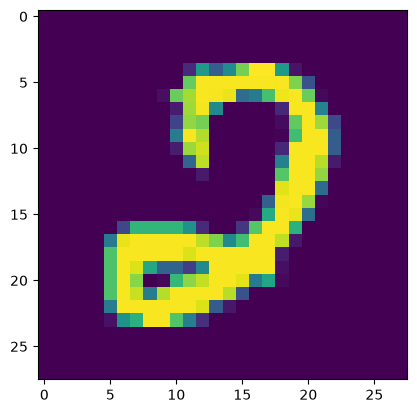

In [32]:
plt.imshow(X_test[400])

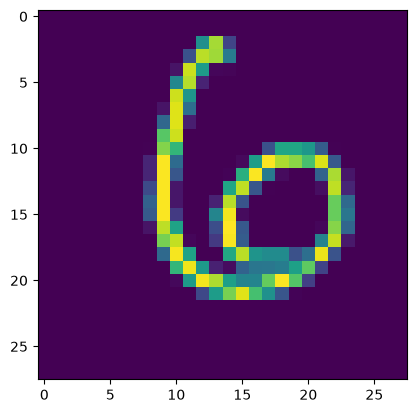

In [33]:
plt.imshow(X_test[100])

In [34]:
import numpy as np
np.argmax(y_pred[20])
# y_pred[400]

9

## Final Output

In [35]:
# from PIL import Image, ImageOps

In [36]:
# img_path = r"/Users/prabu/Documents/AI_Coach_John/Gen AI & Agentic AI /Deep-Learning/ImageClassification/number5.png"

In [37]:
# image = Image.open(img_path)
# image = image.convert(mode="L").resize(size= (28,28))
# image = ImageOps.invert(image)
# image = np.array(image)

# print (image)

In [38]:
# model.save("digital.intel.h5")

In [39]:
# from keras.models import load_model
# digits_intelligence_file = load_model("digital.intel.h5")

In [40]:
# def predict_image(image):
#     image = image/255.0
#     image = np.expand_dims(a = image , axis=0)
#     print (image.shape)
#     prediction = digits_intelligence_file.predict(image)
#     return np.argmax(prediction)

In [41]:
# predict_image(image)

In [42]:
from PIL import Image, ImageOps

In [58]:
img_path = r"/Users/prabu/Documents/AI_Coach_John/Gen AI & Agentic AI /Deep-Learning/ImageClassification/number7.png"

In [60]:
image = Image.open(img_path).convert(mode="L").resize(size=(28, 28))
image = ImageOps.invert(image)  # <-- Invert colors so digit is white on black background
image = image.point(lambda p: 255 if p > 100 else 0)
image = np.array(image)

print(predict_image(image))

(1, 28, 28)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1


In [61]:
model.save('digital7.intel.h5')

In [51]:
from keras.models import load_model
number7 = load_model("digital7.intel.h5")
print (number7)

<Sequential name=sequential, built=True>


In [53]:
def predict_image(image):
    image= image/255.0
    image= np.expand_dims(a=image, axis=0) #--> expecting some format
    print (image.shape)
    prediction = number7.predict(image)
    return np.argmax(prediction)

In [54]:
predict_image(image)

(1, 28, 28)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step


8